# Clustering iris flowers (v2)

<a href="https://colab.research.google.com/github/Aadharsh21/ML-Projects/blob/main/notebooks/04-iris-clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Can an algorithm that never sees the species labels rediscover the three iris species from four measurements?

The first version ([`notebooks/v1/clustering.ipynb`](v1/clustering.ipynb)) ran k-means with k=3 and k=6 and plotted
the clusters (its k=6 plot drew the k=3 model's centres by mistake). It never checked whether the clusters meant
anything. This version measures that, and finds a better method:

| k=3, scored against the real species | Adjusted Rand index | Flowers in their species' cluster |
|---|---|---|
| k-means, raw measurements (v1) | 0.730 | 89.3% |
| k-means, standardized | 0.620 | 83.3% |
| Agglomerative (Ward) | 0.731 | 89.3% |
| **Gaussian mixture, full covariance** | **0.904** | **96.7%** |

Code: [`ml/clustering.py`](../ml/clustering.py).

In [1]:
# Setup: runs from a local clone, or in Google Colab (it clones the repo first)
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("ML-Projects"):
        !git clone -q https://github.com/Aadharsh21/ML-Projects.git
    %cd ML-Projects
    %pip install -q "lightgbm>=4.3"
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from ml import clustering, data, plotting as P

P.style()
pd.set_option("display.precision", 3)

## 1. The data

Fisher's 1936 measurements of 50 flowers from each of three species, in centimetres. The species labels are kept
aside: the algorithms only see the four measurements, and the labels are used afterwards to grade them.

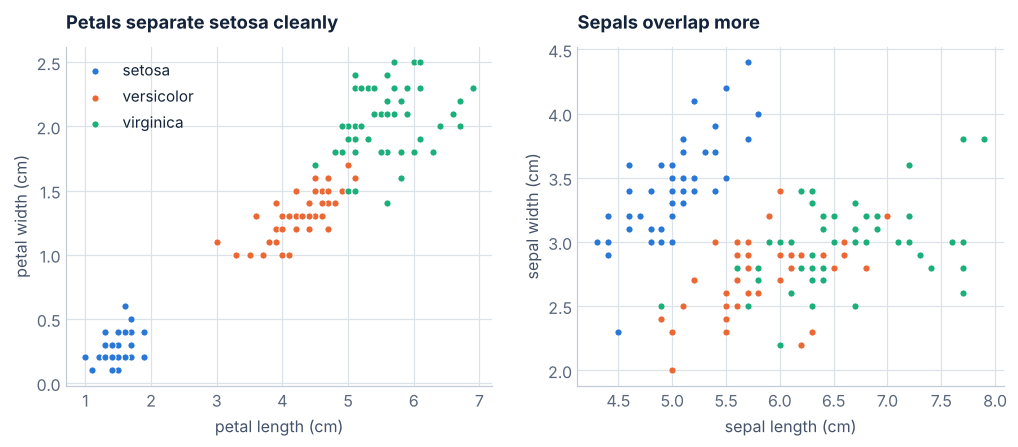

In [3]:
df = data.load_iris()
X = df[clustering.FEATURES].to_numpy()
species = df["species"].cat.codes.to_numpy()
names = list(df["species"].cat.categories)
colors = [P.BLUE, P.ORANGE, P.AQUA]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (a, b) in zip(axes, [("petal_length", "petal_width"), ("sepal_length", "sepal_width")]):
    for k, name in enumerate(names):
        mask = species == k
        ax.scatter(df.loc[mask, a], df.loc[mask, b], s=22, color=colors[k], ec="white", lw=0.6, label=name)
    ax.set_xlabel(a.replace("_", " ") + " (cm)")
    ax.set_ylabel(b.replace("_", " ") + " (cm)")
axes[0].set_title("Petals separate setosa cleanly")
axes[1].set_title("Sepals overlap more")
axes[0].legend(loc="upper left")
plt.show()

Setosa stands apart. Versicolor and virginica touch and overlap, which is the whole difficulty.

## 2. How many clusters?

Two standard ways to pick k without labels: the **elbow** in the within-cluster sum of squares (inertia), and the
**silhouette** score (how much closer each point is to its own cluster than to the next one, from -1 to 1).

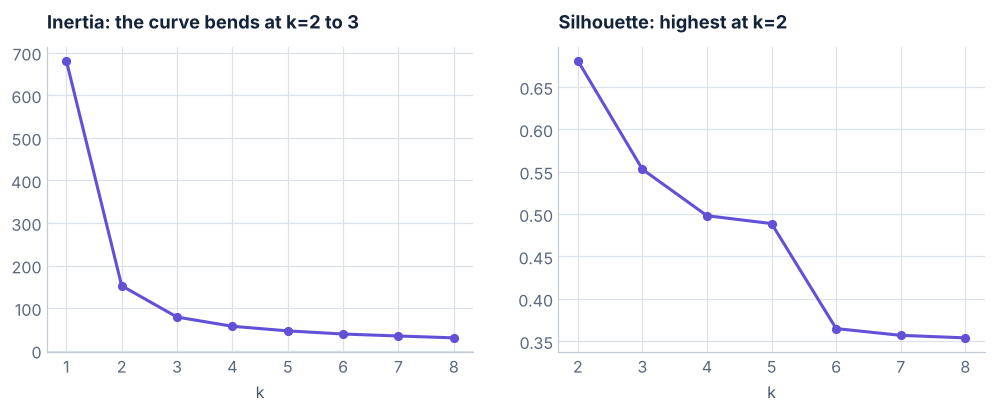

k,1,2,3,4,5,6,7,8
inertia,681.371,152.348,78.851,57.228,46.446,39.040,34.420,30.014
silhouette,NaN,0.681,0.553,0.498,0.489,0.365,0.357,0.354
ari,0.000,0.540,0.730,0.650,0.608,0.448,0.481,0.440


In [4]:
sweep = pd.DataFrame(clustering.sweep(X, species)).set_index("k")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax.plot(sweep.index, sweep["inertia"], color=P.VIOLET, marker="o", ms=5)
ax.set_title("Inertia: the curve bends at k=2 to 3")
ax.set_xlabel("k")
ax2.plot(sweep.index[1:], sweep["silhouette"].iloc[1:], color=P.VIOLET, marker="o", ms=5)
ax2.set_title("Silhouette: highest at k=2")
ax2.set_xlabel("k")
P.save(fig, "iris-choosing-k.png")
plt.show()
sweep.T

The elbow is soft: most of the drop is over by k=2 or 3. The silhouette score clearly prefers two clusters, because
without labels versicolor and virginica genuinely look like one group. Neither method can know that a
botanist cares about three species; this is the honest limit of unsupervised learning.

## 3. Does standardizing help?

Scaling every measurement to unit variance is common advice before k-means. Here it backfires:

In [5]:
scaled = pd.DataFrame(clustering.sweep(StandardScaler().fit_transform(X), species)).set_index("k")
pd.DataFrame({"ARI, raw cm": sweep["ari"], "ARI, standardized": scaled["ari"]}).T

k,1,2,3,4,5,6,7,8
"ARI, raw cm",0.0,0.540,0.73,0.650,0.608,0.448,0.481,0.440
"ARI, standardized",0.0,0.568,0.62,0.473,0.420,0.356,0.409,0.399


Petal length and width carry most of the species signal and also have the largest spread. Standardizing shrinks them
to the same weight as sepal width, the noisiest measurement, so the clusters drift away from the species. Scaling is a
modelling choice, not a reflex.

## 4. k-means vs a Gaussian mixture

k-means draws boundaries as if every cluster were a round blob of the same size. The iris species are elongated
(petal length and width grow together), so a Gaussian mixture with a full covariance matrix per component can fit
them much better. Both at k=3, plus Ward's agglomerative clustering for reference:

In [6]:
km = KMeans(n_clusters=3, n_init=20, random_state=0).fit(X)
gmm = GaussianMixture(3, covariance_type="full", n_init=10, random_state=0).fit(X)
labels = {"k-means": km.labels_, "Gaussian mixture": gmm.predict(X)}
for name, lab in labels.items():
    out = clustering.matched_confusion(species, lab)
    print(f"{name}: ARI {adjusted_rand_score(species, lab):.3f}, "
          f"{out['matched_accuracy']:.1%} of flowers in their species' cluster")
    print(pd.DataFrame(out["matrix"], index=names, columns=["cluster A", "cluster B", "cluster C"]), "\n")

k-means: ARI 0.730, 89.3% of flowers in their species' cluster
            cluster A  cluster B  cluster C
setosa             50          0          0
versicolor          0         48          2
virginica           0         14         36 

Gaussian mixture: ARI 0.904, 96.7% of flowers in their species' cluster
            cluster A  cluster B  cluster C
setosa             50          0          0
versicolor          0         45          5
virginica           0          0         50 



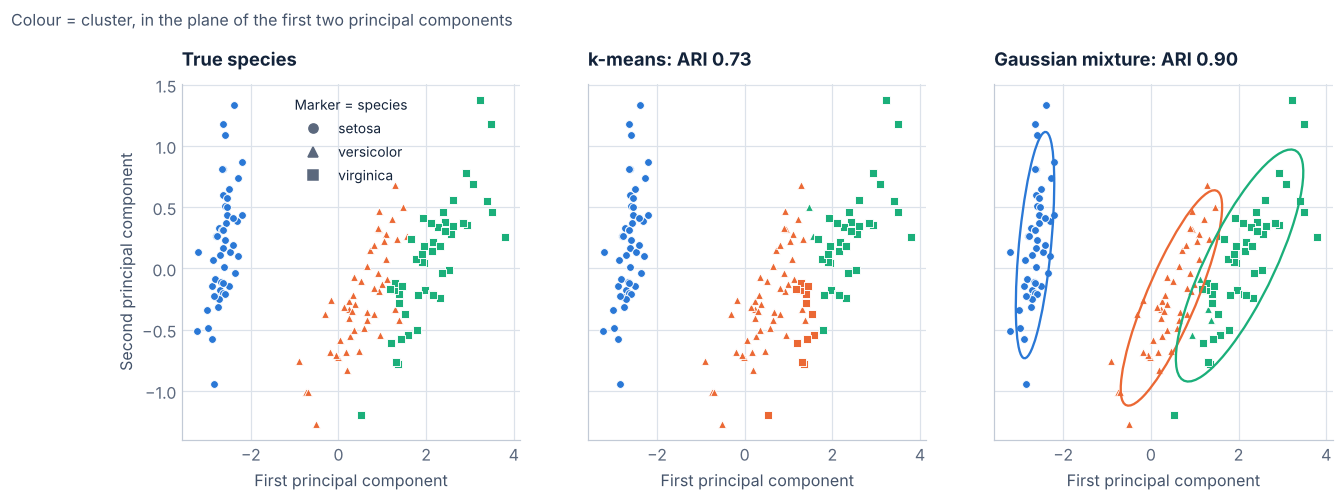

In [7]:
pca = PCA(2).fit(X)
Z = pca.transform(X)

def species_of_cluster(lab):
    """Map each cluster to the species most of its flowers belong to, so colours line up."""
    return {k: int(np.bincount(species[lab == k], minlength=3).argmax()) for k in np.unique(lab)}

def draw(ax, lab, title):
    colour_of = species_of_cluster(lab)
    for k in np.unique(lab):
        for sp, marker in enumerate(["o", "^", "s"]):
            mask = (lab == k) & (species == sp)
            ax.scatter(Z[mask, 0], Z[mask, 1], s=26, marker=marker, color=colors[colour_of[k]], ec="white", lw=0.6)
    ax.set_title(title)
    ax.set_xlabel("First principal component")
    return colour_of

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
draw(axes[0], species, "True species")
draw(axes[1], km.labels_, f"k-means: ARI {adjusted_rand_score(species, km.labels_):.2f}")
gmm_labels = gmm.predict(X)
colour_of = draw(axes[2], gmm_labels, f"Gaussian mixture: ARI {adjusted_rand_score(species, gmm_labels):.2f}")
W = pca.components_
for k in range(3):
    vals, vecs = np.linalg.eigh(W @ gmm.covariances_[k] @ W.T)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    centre = pca.transform(gmm.means_[k:k + 1])[0]
    # two standard deviations along each axis
    axes[2].add_patch(Ellipse(centre, 4 * np.sqrt(vals[1]), 4 * np.sqrt(vals[0]), angle=angle,
                              fill=False, ec=colors[colour_of[k]], lw=1.5))
axes[0].set_ylabel("Second principal component")
handles = [plt.Line2D([], [], marker=m, ls="", color=P.INK_3, label=n) for m, n in zip(["o", "^", "s"], names)]
axes[0].legend(handles=handles, title="Marker = species", loc="upper center", fontsize=9, title_fontsize=9)
fig.suptitle("Colour = cluster, in the plane of the first two principal components", x=0.01, y=1.04, ha="left",
             fontsize=10.5, color=P.INK_2)
P.save(fig, "iris-kmeans-vs-gmm.png")
plt.show()

k-means cuts straight through the overlap between versicolor and virginica and hands a chunk of virginica to the
versicolor cluster. The mixture's components stretch along the direction the flowers actually vary (the ellipses
show two standard deviations), so only a handful of flowers end up with the wrong group.

## 5. Does the mixture also think there are three species?

The Bayesian information criterion (BIC) trades fit against the number of parameters; lower is better.

In [8]:
bic = pd.Series({k: GaussianMixture(k, covariance_type="full", n_init=10, random_state=0).fit(X).bic(X)
                 for k in range(1, 7)}, name="BIC")
bic.to_frame().T

,1,2,3,4,5,6
BIC,829.978,574.018,580.859,622.173,669.831,683.631


BIC narrowly prefers two components over three. Like the silhouette score, it is telling the truth about the data:
two of the species are hard to tell apart from these four measurements alone. Given k=3, though, the mixture recovers
the species far better than k-means.

## 6. Export for the browser

`python -m ml clustering` writes the measurements, this analysis and reference k-means and EM runs to
`web/public/data/iris/`. The browser implementations in [`web/src/ml/clustering.ts`](../web/src/ml/clustering.ts)
step through one iteration at a time (so a page can animate them) and match scikit-learn's `GaussianMixture`
step for step in the tests.

## Limitations

- **Iris is tiny and famous.** 150 flowers is a teaching dataset; the lessons (check what clusters mean, choose
  scaling deliberately, match the model to the cluster shape) carry over, the numbers don't.
- **Labels were used to grade, never to fit.** In a real unsupervised problem there is no answer key, which is
  exactly when the disagreement between silhouette, elbow and BIC matters most.